# Шаг 8. GeoNames в Google Colab

Блокнот рассчитан на срез из 200 000 строк. В Colab файл загружается через диалог. При локальном запуске используется срез из каталога проекта.

## 1. Версия интерпретатора

В курсе требуется Python 3.12.14; версию в Colab задаёт сервис.

In [1]:
!python --version
import sys
print(sys.version)
print('совпадает с 3.12.14:', sys.version.split()[0] == '3.12.14')

Python 3.13.18
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
совпадает с 3.12.14: False


## 2. Установка библиотек

Команды с `!` выполняются в оболочке сеанса.

In [2]:
from importlib.util import find_spec
IN_COLAB = find_spec('google') is not None and find_spec('google.colab') is not None
if IN_COLAB:
    !pip install -q pandas polars
import pandas as pd, polars as pl
print('pandas', pd.__version__)
print('polars', pl.__version__)

pandas 2.2.3
polars 1.35.2


## 3. Загрузка среза

Файл загружается с компьютера окном выбора (или через Google Диск).

In [3]:
from pathlib import Path
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    path = next(iter(uploaded))
else:
    root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
    path = root / 'data' / 'interim' / 'geonames_sample.csv'

Saving geonames_sample.csv to geonames_sample.csv


## 4. Чтение и сводка

Кавычки отключены (в файле нет экранирования), `NA` - это код Намибии, а не пропуск.

In [4]:
import csv
df = pd.read_csv(path, quoting=csv.QUOTE_NONE, keep_default_na=False, na_values=[''], low_memory=False)
print('строк и столбцов:', df.shape)
summary = pd.DataFrame({'тип': df.dtypes.astype(str), 'доля пропусков': df.isna().mean().round(4)})
summary

строк и столбцов: (200000, 19)


,тип,доля пропусков
geonameid,int64,0.0000
name,object,0.0000
asciiname,object,0.0000
alternatenames,object,0.5157
latitude,float64,0.0000
longitude,float64,0.0000
feature class,object,0.0004
feature code,object,0.0084
country code,object,0.0005
cc2,object,0.9722


## 5. График: число объектов по году последнего изменения

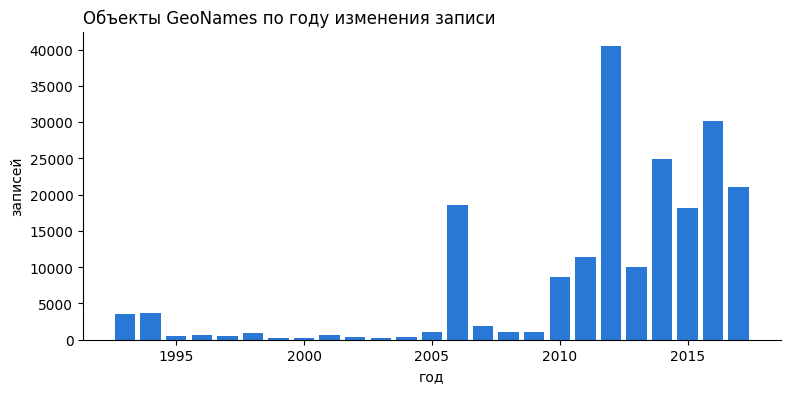

In [5]:
import matplotlib.pyplot as plt
years = pd.to_datetime(df['modification date']).dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(years.index, years.values, color='#2a78d6')
ax.set_title('Объекты GeoNames по году изменения записи', loc='left')
ax.set_xlabel('год'); ax.set_ylabel('записей')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## Вывод

Версию Python нужно сверять с выводом первой ячейки. После завершения облачного сеанса загруженные файлы и установленные пакеты могут потребовать повторной подготовки.